# Galaxy Zoo 2: Class imbalance in the deep questions

Every architecture in the benchmark is weak on the same questions deep in the decision
tree, and almost never predicts their rare answers, such as `boxy` bulges (Q8) or more
than four spiral arms (Q10). This notebook tests two standard remedies:

- **class reweighting**: within each question, the loss of a galaxy is multiplied by
  1 / (C · prior) of its majority-vote answer, so every answer carries the same total
  weight;
- **oversampling**: galaxies whose answer to Q8, Q9 or Q10 is rare are drawn more often
  (weight 1 / prior, capped at 10, epoch length unchanged).

Each configuration, including the baseline without either, is trained with DenseNet-121
on the same ten seeds (`scripts/run_class_imbalance.sh`), so its effect can be compared
with the seed-to-seed spread of the baseline.

In [1]:
import json
import re
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, data, sampling
from src.dataset import load_splits

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

CONFIGS = {
    "baseline": ("baseline", "#7F7F7F"),
    "classweight": ("class reweighting", "#DD8452"),
    "oversample": ("oversampling", "#4C72B0"),
}

## Training signal analysis

The D-M loss of a question grows with the number of votes on it, and so does its share of
the gradient. Summed over the training set, the votes, and with them the training signal,
are concentrated in the questions at the top of the tree.

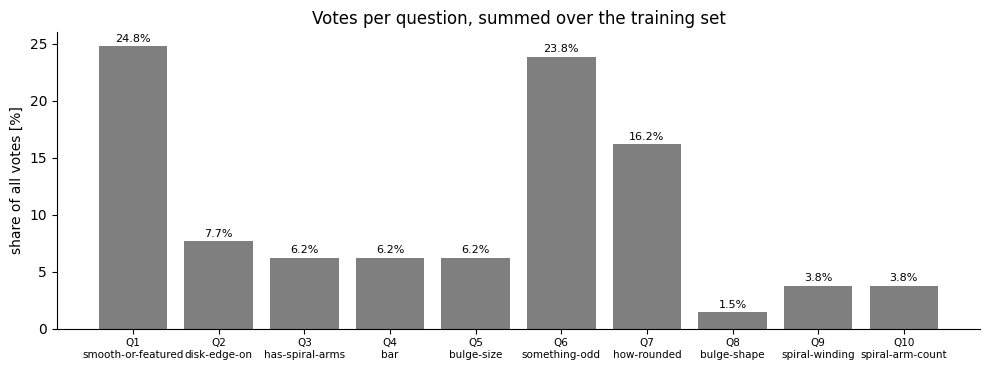

In [2]:
train, _, _ = load_splits()
votes = train.select_columns(data.total_vote_cols()).to_pandas().fillna(0)
votes.columns = data.QUESTION_NAMES

share = 100 * votes.sum() / votes.sum().sum()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar([f"Q{q}\n{name}" for q, name in enumerate(data.QUESTION_NAMES, start=1)], share,
       color="#7F7F7F")
for i, v in enumerate(share):
    ax.text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=8)
ax.set_ylabel("share of all votes [%]")
ax.tick_params(axis="x", labelsize=7.5)
ax.set_title("Votes per question, summed over the training set")
fig.tight_layout()
plt.show()

## Weighting

Class weights for the two questions with the rarest answers, and how many times more
often oversampling draws a galaxy of each answer than the average galaxy.

In [3]:
labels = sampling.question_labels(train)
priors = sampling.class_priors(labels)
class_weights = sampling.class_balanced_weights(labels)
sample_weights = sampling.deep_sample_weights(labels).numpy()

tables = []
for q in (7, 9):
    name, answers = data.QUESTIONS[q]
    tables.append(pd.DataFrame(
        {
            "prior [%]": 100 * priors[q],
            "class weight": class_weights[q].numpy(),
            "oversampling ×": [
                sample_weights[labels[:, q] == i].mean() for i in range(len(answers))
            ],
        },
        index=pd.MultiIndex.from_product([[f"Q{q + 1} {name}"], answers]),
    ))
pd.concat(tables).round(2)

prior [%]  class weight  oversampling ×
Q8 bulge-shape       round            78.16          0.43            0.92
                     boxy              5.16          6.46            3.01
                     no-bulge         16.67          2.00            1.92
Q10 spiral-arm-count 1                 7.60          2.19            3.01
                     2                42.32          0.39            1.21
                     3                 3.17          5.27            3.01
                     4                 1.18         14.10            3.01
                     more-than-4       2.34          7.13            3.01
                     cant-tell        43.40          0.38            0.96

## Results

Test-set metrics of every run, summarised as mean ± standard deviation over the ten seeds
of each configuration. F1 and AUC of an answer treat it as one class against the rest;
AUC measures how well the predicted fraction ranks galaxies, independently of the
decision threshold.

In [5]:
RUN_NAME = re.compile(r"imbalance_(baseline|classweight|oversample)_s(\d+)")

rows = []
for path in sorted((config.RESULTS_DIR / "runs").glob("imbalance_*.json")):
    run = json.loads(path.read_text())
    cfg, seed = RUN_NAME.fullmatch(run["run_name"]).groups()
    q8, q10 = run["test"]["questions"][7], run["test"]["questions"][9]
    boxy, many = q8["answers"].index("boxy"), q10["answers"].index("more-than-4")
    rows.append({
        "config": cfg,
        "seed": int(seed),
        "test wRMSE": run["test"]["wrmse"],
        "mean F1": run["test"]["mean_f1"],
        "Q8 F1": q8["f1_macro"],
        "boxy F1": q8["f1"][boxy],
        "boxy AUC": q8["auc"][boxy],
        "Q10 F1": q10["f1_macro"],
        "more-than-4 F1": q10["f1"][many],
        "more-than-4 AUC": q10["auc"][many],
    })
runs = pd.DataFrame(rows)
print(runs.groupby("config").size().to_string())

metric_cols = [c for c in runs.columns if c not in ("config", "seed")]
grouped = runs.groupby("config")[metric_cols]
mean, std = grouped.mean(), grouped.std()
pd.DataFrame(
    {label: [f"{mean.at[c, m]:.4f} ± {std.at[c, m]:.4f}" for m in metric_cols]
     for c, (label, _) in CONFIGS.items()},
    index=metric_cols,
)

config
baseline       10
classweight    10
oversample     10


,baseline,class reweighting,oversampling
test wRMSE,0.0911 ± 0.0002,0.0974 ± 0.0005,0.0944 ± 0.0005
mean F1,0.7395 ± 0.0027,0.7352 ± 0.0018,0.7388 ± 0.0030
Q8 F1,0.4910 ± 0.0026,0.4798 ± 0.0054,0.5015 ± 0.0065
boxy F1,0.0087 ± 0.0044,0.1566 ± 0.0029,0.0473 ± 0.0214
boxy AUC,0.6377 ± 0.0071,0.7095 ± 0.0021,0.6949 ± 0.0031
Q10 F1,0.4070 ± 0.0097,0.4313 ± 0.0041,0.4227 ± 0.0081
more-than-4 F1,0.2009 ± 0.0201,0.1923 ± 0.0078,0.2154 ± 0.0166
more-than-4 AUC,0.8408 ± 0.0042,0.8627 ± 0.0032,0.8569 ± 0.0047


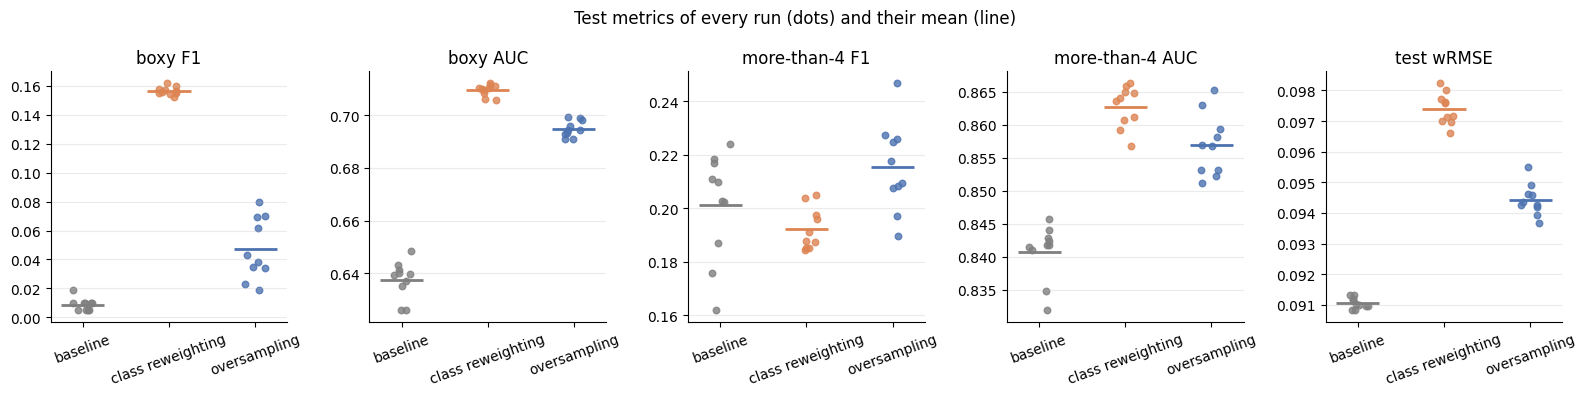

In [7]:
metrics = ["boxy F1", "boxy AUC", "more-than-4 F1", "more-than-4 AUC", "test wRMSE"]
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, len(metrics), figsize=(16, 4))
for ax, metric in zip(axes, metrics, strict=True):
    for x, (cfg, (_, color)) in enumerate(CONFIGS.items()):
        values = runs.loc[runs["config"] == cfg, metric]
        ax.scatter(x + rng.uniform(-0.12, 0.12, len(values)), values, color=color, s=22, alpha=0.8)
        ax.hlines(values.mean(), x - 0.25, x + 0.25, color=color, lw=2)
    ax.set_xticks(range(len(CONFIGS)))
    ax.set_xticklabels([label for label, _ in CONFIGS.values()], rotation=20)
    ax.set_title(metric)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Test metrics of every run (dots) and their mean (line)")
fig.tight_layout()
fig.savefig(FIG_DIR / "imbalance_results.png", dpi=150, bbox_inches="tight")
plt.show()

## Prediction change for Q8

Confusion matrices summed over the ten runs of each configuration and normalised by row,
so the diagonal is the recall of each answer.

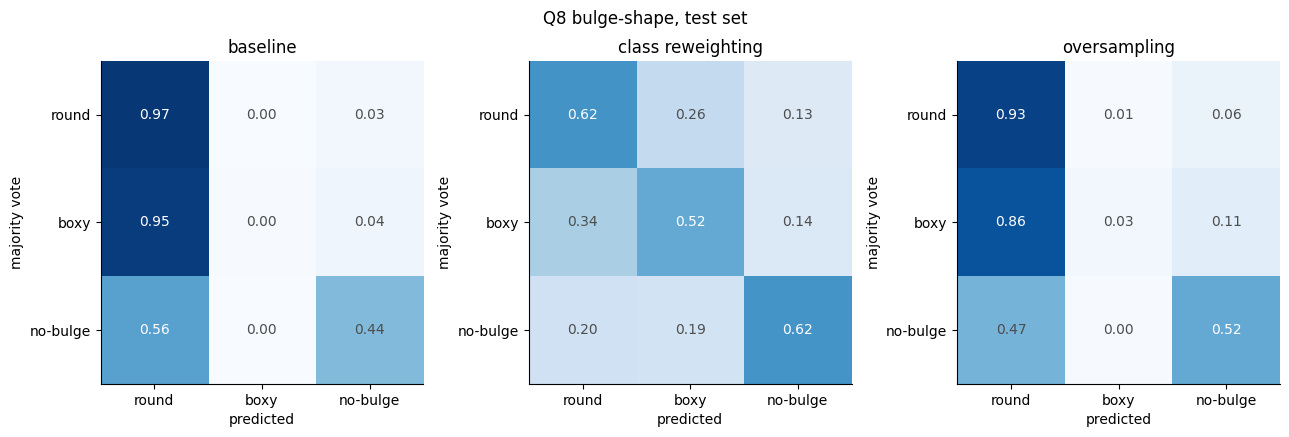

In [6]:
def summed_confusion(cfg: str, q: int) -> np.ndarray:
    total = 0
    for path in sorted((config.RESULTS_DIR / "runs").glob(f"imbalance_{cfg}_s*.json")):
        question = json.loads(path.read_text())["test"]["questions"][q - 1]
        total = total + np.array(question["confusion"])
    return total / total.sum(axis=1, keepdims=True)


answers = data.QUESTIONS[7][1]
fig, axes = plt.subplots(1, len(CONFIGS), figsize=(13, 4.3))
for ax, (cfg, (label, _)) in zip(axes, CONFIGS.items(), strict=True):
    cm = summed_confusion(cfg, 8)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(answers)))
    ax.set_xticklabels(answers)
    ax.set_yticks(range(len(answers)))
    ax.set_yticklabels(answers)
    ax.set_xlabel("predicted")
    ax.set_ylabel("majority vote")
    ax.set_title(label)
    for i in range(len(answers)):
        for j in range(len(answers)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "0.3")
fig.suptitle("Q8 bulge-shape, test set")
fig.tight_layout()
fig.savefig(FIG_DIR / "imbalance_confusion_q8.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

Over ten seeds the baseline is very stable (test wRMSE 0.0911 ± 0.0002), so the effects below
are large compared with the seed-to-seed spread, except where noted.

- **The rare answers can be learned, but the models do not predict them by default.** Both
  interventions raise the AUC of `boxy` (0.638 → 0.710 with reweighting, 0.695 with
  oversampling) and of `more-than-4` (0.841 → 0.863 / 0.857), and none of the runs
  overlaps with the baseline. The predicted fractions therefore rank these galaxies better,
  not only after a shift of the decision threshold.
- **Reweighting moves the decisions in Q8.** Recall of `boxy` rises from 0.4% to 52%, and its
  F1 from 0.01 to 0.16. This comes at the cost of `round`, whose recall drops from 0.97 to
  0.62, so the macro F1 of Q8 falls slightly (0.491 → 0.480). Oversampling is milder: `boxy`
  F1 0.05, Q8 macro F1 up to 0.502.
- **`more-than-4` F1 does not change.** For both interventions the difference from the
  baseline (−0.009 and +0.015) is smaller than the baseline's own spread (± 0.020). Macro F1 of
  Q10 improves a little (0.407 → 0.431 / 0.423), mostly through the other rare answers.
- **Both interventions make the vote fractions worse.** Test wRMSE rises from 0.0911 to 0.0974
  with reweighting and 0.0944 with oversampling, and mean F1 over all questions does not
  improve. Reweighting changes the target distribution the model is fitted to, so its
  predicted fractions are no longer estimates of the volunteers' votes.

The interventions trade the quality of the predicted vote fractions for decisions on a few
rare answers. They help where the answer is visually distinct but rare (`boxy`); they do
not help where the label itself is noisy (`more-than-4`, counted from a median of four
votes). For the main task, predicting vote fractions, the baseline remains the best choice.